# Tarea 2 · Parte 2: de los modelos base a la extracción estructurada

**Pregunta guía:** ¿pueden convertir documentos escaneados y entrevistas en audio en un archivo de
texto estructurado y buscable?

La Parte 1 (`01_extraccion.ipynb`) sacó el texto de 25 documentos con PaddleOCR y de 28 clips con
faster-whisper. Este notebook mide qué tan bueno es ese texto, lo compara con otros dos modelos y lo
convierte en campos estructurados con un LLM.

| Sección | Paso del enunciado | Resultado |
|---|---|---|
| 1 | Muestra de evaluación | 10 documentos y 10 clips de la Parte 1, transcritos a mano: columna `texto_referencia` |
| 2 | Línea base sin ajuste | CER de PaddleOCR y WER de faster-whisper `small` en CPU |
| 3 | Extracción estructurada con LLM y auditoría humana | `datos/extraccion_llm.csv` y 20 extracciones revisadas a mano |
| 4 | Mejora y comparación de modelos | EasyOCR frente a PaddleOCR (CER) y Qwen3-ASR frente a faster-whisper (WER y latencia), en los mismos archivos |
| 5 | Casos difíciles | Manuscritos y fotos; entrevistas de calle con ruido frente a lecturas de estudio |
| 6 | Comparativa y decisión | Tabla de los cuatro modelos y elección para un entorno real |

**Reglas de la evaluación.** La muestra, los cuatro modelos con sus parámetros, el prompt del LLM y los
criterios de auditoría quedaron fijos el 24 de octubre de 2026. La normalización de textos quedó fija
el 25 de octubre. Todo se fijó antes de calcular cualquier métrica y está en
`modelos/configuracion_evaluacion.json`. Ningún parámetro se ajustó mirando los resultados. Las
referencias son transcripciones manuales hechas sin ver la salida de ningún modelo.

**Entorno.** Es el mismo `.venv` de la Parte 1 (versiones exactas en `requirements-notebooks.txt`).
Todo corre en CPU: Intel i7-3770S (4 núcleos, sin AVX2) con 16 GB de RAM y sin GPU. EasyOCR corre en
un entorno aparte (sección 4.1). Los modelos corren en local, así que ningún texto ni audio sale de la
computadora.

**Privacidad.** Las referencias manuales y las salidas de los modelos alternativos se seudonimizan con
el mismo diccionario y la misma función de la Parte 1 antes de mostrarse o guardarse. Este notebook
solo muestra textos seudonimizados y conteos.

**Reproducir.** Las salidas pesadas de los modelos están en `datos/raw/` (fuera de Git). Si existen, el
notebook las lee; si no, vuelve a correr cada modelo. Para ejecutarlo:
`.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace 02_evaluacion.ipynb`.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # torch y CTranslate2 traen su propio OpenMP

import json
import platform
import random
import re
import subprocess
import time
import warnings
from datetime import date
from importlib.metadata import version
from pathlib import Path

import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

import voz  # módulo de la Sesión 13 (copiado en esta carpeta)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de tqdm al importar el VAD
pio.renderers.default = "plotly_mimetype+png"   # interactivo en Jupyter/VS Code y PNG visible en GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 900, 480
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

BASE = Path.cwd()
DATOS = BASE / "datos"
RAW = DATOS / "raw"
REFERENCIAS = RAW / "muestra_evaluacion"               # transcripciones manuales (.txt) de la muestra
EVAL_DIR = RAW / "evaluacion"                          # salidas crudas de los modelos alternativos
LLM_JSONL = RAW / "llm" / "extracciones.jsonl"          # salidas crudas del LLM
AUDITORIA_XLSX = RAW / "auditoria_llm" / "auditoria_llm.xlsx"
SALIDA = DATOS                                          # carpeta de los CSV que publica este notebook
SALIDA.mkdir(parents=True, exist_ok=True)

CONFIG = json.loads((BASE / "modelos" / "configuracion_evaluacion.json").read_text(encoding="utf-8"))
documentos = pd.read_csv(DATOS / "documentos.csv")
transcripciones = pd.read_csv(DATOS / "transcripciones.csv")
fuentes = pd.read_csv(DATOS / "fuentes.csv")
print(f"Corpus de la Parte 1: {len(documentos)} documentos y {len(transcripciones)} clips "
      f"({transcripciones['duracion_seg'].sum() / 60:.1f} min)")
print(f"Configuración fijada el {CONFIG['fecha_fijada']} (modelos/configuracion_evaluacion.json)")

Corpus de la Parte 1: 25 documentos y 28 clips (42.4 min)
Configuración fijada el 2026-10-24 (modelos/configuracion_evaluacion.json)


In [2]:
paquetes = ["jiwer", "faster-whisper", "paddleocr", "transformers", "torch", "spacy", "rapidfuzz", "plotly", "pandas"]
print(f"Python {platform.python_version()} | {platform.system()} {platform.release()} | {platform.processor()}")
pd.Series({p: version(p) for p in paquetes}, name="versión").to_frame().T

Python 3.12.14 | Windows 10 | Intel64 Family 6 Model 58 Stepping 9, GenuineIntel


,jiwer,faster-whisper,paddleocr,transformers,torch,spacy,rapidfuzz,plotly,pandas
versión,4.0.0,1.2.1,3.7.0,5.20.2,2.14.1,3.8.16,3.14.6,7.1.0,3.1.0


## 1. Muestra de evaluación (sin datos nuevos)

Los 20 archivos salen del corpus de la Parte 1. No se recolectó nada nuevo. La selección es aleatoria
y estratificada, con semilla fija 2026, y se hizo el 24 de octubre, antes de calcular cualquier métrica:

- **Documentos:** 3 impresos, 3 fotos y 4 manuscritos, en proporción a los 8, 8 y 9 del corpus.
- **Clips:** 4 frases leídas de OpenSLR 73 (grabación de estudio, una voz) y 6 entrevistas de
  Wikimedia Commons (grabación de campo). Las entrevistas son de distintas condiciones: una marcha en la
  calle, fiestas patronales de la sierra y testimonios en San Martín, con una o varias voces. Solo
  entraron al sorteo las entrevistas de hasta 100 s, por el tiempo que toma transcribirlas a mano. Por
  eso no hay clips de Radio Bomba, que duran más de 3 minutos.

La celda siguiente repite el sorteo con la misma semilla y comprueba que da los mismos 20 archivos.

In [3]:
SEMILLA = CONFIG["muestra"]["semilla"]
estratos_doc = CONFIG["muestra"]["documentos"]["estratos"]
estratos_aud = CONFIG["muestra"]["audio"]["estratos"]

muestra_docs = pd.concat(documentos[documentos["tipo"] == t].sample(n, random_state=SEMILLA) for t, n in estratos_doc.items())
candidatos = transcripciones[(transcripciones["fuente"] == "OpenSLR 73") | (transcripciones["duracion_seg"] <= 100)]
muestra_clips = pd.concat(candidatos[candidatos["fuente"] == f].sample(n, random_state=SEMILLA) for f, n in estratos_aud.items())
IDS_DOC, IDS_AUD = sorted(muestra_docs["id"]), sorted(muestra_clips["id"])
assert IDS_DOC == CONFIG["muestra"]["documentos"]["ids"] and IDS_AUD == CONFIG["muestra"]["audio"]["ids"]
print("El sorteo reproduce la muestra fijada el", CONFIG["fecha_fijada"])

descripcion = fuentes.set_index("id")["descripcion"]
tabla_muestra = pd.concat([
    muestra_docs.sort_values("id").assign(modalidad="documento", tipo_o_fuente=muestra_docs["tipo"],
                        tamaño=muestra_docs["caracteres"].astype(str) + " caracteres de OCR"),
    muestra_clips.sort_values("id").assign(modalidad="audio", tipo_o_fuente=muestra_clips["fuente"] + " (" + muestra_clips["tipo"] + ")",
                         tamaño=muestra_clips["duracion_seg"].map(lambda s: f"{s:.1f} s")),
])[["id", "modalidad", "tipo_o_fuente", "tamaño"]].reset_index(drop=True)
tabla_muestra["descripción"] = tabla_muestra["id"].map(descripcion)
print(f"Documentos: {muestra_docs['tipo'].value_counts().to_dict()} | "
      f"Audio: {muestra_clips['fuente'].value_counts().to_dict()}, {muestra_clips['duracion_seg'].sum() / 60:.1f} min")
tabla_muestra

El sorteo reproduce la muestra fijada el 2026-10-24
Documentos: {'manuscrito': 4, 'impreso': 3, 'foto': 3} | Audio: {'Wikimedia Commons': 6, 'OpenSLR 73': 4}, 6.8 min


,id,modalidad,tipo_o_fuente,tamaño,descripción
0,doc_004,documento,impreso,935 caracteres de OCR,"Constitución Política del Perú reformada por el Congreso de 1860 (Lima, Imprenta de Jo..."
1,doc_005,documento,impreso,1076 caracteres de OCR,"Drama en verso «El amor y el oro» (Lima, 1861), acto I, escena X"
2,doc_006,documento,impreso,2403 caracteres de OCR,"Libro «Tradiciones peruanas», tomo I (c. 1893), página 33"
3,doc_012,documento,foto,161 caracteres de OCR,"Foto de una placa de bronce oscuro a un poeta del virreinato, autor de «La Cristiada» ..."
4,doc_013,documento,foto,56 caracteres de OCR,Foto de un letrero de letras metálicas con sombra sobre muro de piedra (Paraninfo Univ...
5,doc_014,documento,foto,104 caracteres de OCR,Foto inclinada del letrero del Antiguo Hospital de los Bethlemitas sobre muro desgasta...
6,doc_020,documento,manuscrito,107 caracteres de OCR,Pizarra rotulada a mano de una cevichería del Mercado de Cusco (2011)
7,doc_023,documento,manuscrito,88 caracteres de OCR,Cartel escrito a mano «Si tu familia no acepta tu orientación sexual…» (Marcha del Org...
8,doc_025,documento,manuscrito,197 caracteres de OCR,"Letrero pintado a mano con la carta de un recreo campestre (Ingenio, Junín)"
9,doc_026,documento,manuscrito,23 caracteres de OCR,"Cartel escrito a mano «Mi amor por ti es incondicional» (Marcha del Orgullo, Lima, 202..."


### Transcripción manual

Cada archivo de la muestra se transcribió a mano en un `.txt` (`datos/raw/muestra_evaluacion/`), sin
mirar la salida de ningún modelo. Las reglas se fijaron antes de empezar:

- **Documentos:** todo el texto legible, en orden de lectura, un renglón de la imagen por línea. Se copia
  lo escrito aunque tenga faltas o grafía antigua. La «ſ» se escribe «s». Las palabras partidas con guion
  al final del renglón se copian así. Lo que no se puede leer ni con zoom se marca `[ilegible]`.
- **Audio:** todo lo que se dice con claridad, palabra por palabra, con un cambio de línea cuando cambia
  quien habla. No se escriben marcas de hablante, muletillas (eh, mmm) ni repeticiones por tartamudeo.
  Los años y las cantidades van en cifras, las horas en letras, y lo que no se entiende se marca `[inaudible]`.

Antes de calcular métricas, las 4 frases de OpenSLR 73 se cotejaron con el texto oficial del corpus, que
es lo que la persona leyó. Se corrigieron dos diferencias: «reguardar» por «resguardar» (clip_023) y
«la 1 y las 3» por «la una y las tres» (clip_029).

Las referencias se seudonimizan igual que los textos de la Parte 1 y se guardan en la columna
`texto_referencia` de `datos/documentos.csv` y `datos/transcripciones.csv`. Esa columna queda vacía
en los archivos que no están en la muestra.

In [4]:
def leer_referencia(id_):
    ruta = REFERENCIAS / ("documentos" if id_.startswith("doc_") else "audios") / f"{id_}.txt"
    crudo = ruta.read_bytes()
    try:
        texto = crudo.decode("utf-8-sig")
    except UnicodeDecodeError:          # el Bloc de notas antiguo guarda en ANSI
        texto = crudo.decode("cp1252")
    return texto.replace("\r\n", "\n").strip()


refs_crudas = {i: leer_referencia(i) for i in IDS_DOC + IDS_AUD}
vacias = [i for i, t in refs_crudas.items() if not t]
assert not vacias, f"Faltan transcripciones manuales: {vacias}"

marcas = re.compile(r"\[(?:ilegible|inaudible)\]", re.I)
resumen_refs = pd.DataFrame([{"modalidad": "documento" if i.startswith("doc_") else "audio", "archivos": 1,
                              "líneas": t.count("\n") + 1, "palabras": len(t.split()), "caracteres": len(t),
                              "marcas [ilegible] / [inaudible]": len(marcas.findall(t))} for i, t in refs_crudas.items()])
print("Referencias manuales completas: 10 documentos y 10 clips")
resumen_refs.groupby("modalidad").sum()

Referencias manuales completas: 10 documentos y 10 clips


,archivos,líneas,palabras,caracteres,marcas [ilegible] / [inaudible]
modalidad,,,,,
audio,10,50,901,5048,0
documento,10,159,905,5321,0


### Seudonimización de las referencias

Se usa el mismo procedimiento de la Parte 1: patrones de datos personales, el diccionario de nombres
revisado a mano (`datos/raw/seudonimos.json`, fuera de Git) y la comparación difusa de `voz.seudonimizar`.
La misma persona recibe el mismo `[PERSONA_NN]` en la referencia y en la salida de los modelos. Después,
spaCy vuelve a buscar nombres de persona y cada candidato que queda se revisa a mano.

In [5]:
import spacy
nlp = spacy.load("es_core_news_md")

PATRONES = {
    "[CORREO]": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "[DNI]": r"\b(?:DNI|D\.N\.I\.)?\s*[:N°º.]*\s*\d{8}\b",
    "[TELEFONO]": r"\b9\d{2}[\s-]?\d{3}[\s-]?\d{3}\b",
    "[DIRECCION]": r"\b(?:Av\.|Avenida|Jr\.|Jirón|Calle|Psje\.|Pasaje)\s+[A-ZÁÉÍÓÚÑ][\w\s.]{2,40}?\s+(?:N[°º.]?\s*)?\d{2,5}\b",
}
# Diccionario por texto de la Parte 1 (nombre real -> [PERSONA_NN]). Contiene nombres reales: no se versiona.
REEMPLAZOS = json.loads((RAW / "seudonimos.json").read_text(encoding="utf-8"))


def seudonimizar_texto(id_, texto):
    """La misma función de la Parte 1: patrones y diccionario del texto; devuelve el texto y el conteo por categoría."""
    conteo = {}
    for etiqueta, patron in PATRONES.items():
        texto, n = re.subn(patron, etiqueta, texto)
        if n:
            conteo[etiqueta] = conteo.get(etiqueta, 0) + n
    for nombre, seud in REEMPLAZOS.get(id_, {}).items():   # primero los nombres completos, luego las partes
        antes = texto.count(seud)
        exacto = r"(?<!\w)" + r"\s+".join(map(re.escape, nombre.split())) + r"(?!\w)"   # también cortado entre dos líneas
        texto = re.sub(exacto, seud, texto, flags=re.IGNORECASE)
        if len(nombre) > 5:   # en nombres cortos la comparación difusa confunde palabras comunes
            texto = voz.seudonimizar(texto, {nombre: seud}, parecido=85)
        if texto.count(seud) > antes:
            conteo["[PERSONA]"] = conteo.get("[PERSONA]", 0) + texto.count(seud) - antes
    return texto, conteo


def candidatos_per(texto):
    return sorted({e.text.strip() for e in nlp(texto).ents
                   if e.label_ == "PER" and len(e.text.strip()) > 2 and "PERSONA_" not in e.text})


referencias, conteo_refs = {}, {}
for id_, texto in refs_crudas.items():
    referencias[id_], conteo_refs[id_] = seudonimizar_texto(id_, texto)
n_reemplazos = sum(sum(c.values()) for c in conteo_refs.values())
print(f"Referencias: {n_reemplazos} menciones reemplazadas en {sum(bool(c) for c in conteo_refs.values())} de 20 textos")

# Candidatos de spaCy que quedan después de seudonimizar, revisados a mano: ninguno es una persona real
SE_MANTIENEN_REF = {
    # referencias: documentos
    "Consti-": "«Constitución» cortada al final del renglón",
    "ESCENA X.": "encabezado de escena del drama",
    "Doña Isabel": "personaje de ficción del drama «El amor y el oro» (1861)",
    "Leonor": "personaje de ficción del drama «El amor y el oro» (1861)",
    "Dimas de la Tijereta": "personaje de ficción de la tradición",
    "Dimas": "personaje de ficción de la tradición",
    "Tijereta": "personaje de ficción de la tradición",
    "Visitación": "personaje de ficción de la tradición",
    "Lilit": "demonio, personaje de la tradición",
    "Satanás": "demonio, personaje de la tradición",
    "Majestad Infernal": "tratamiento que la tradición da al demonio",
    "Concédele": "verbo, no un nombre",
    "Item": "«ítem» de las cláusulas del contrato, no un nombre",
    "Tigre\nCanchita": "plato de la carta (leche de tigre con canchita)",
    "Tigre Canchita": "plato de la carta (leche de tigre con canchita)",
    "Arroz Chaufa": "plato de la carta",
    "Chilcano Represco": "bebidas de la carta (chilcano, refresco)",
    # referencias: audio
    "Bueno": "palabra común",
    "Claro": "palabra común",
    "Entonces": "palabra común",
    "Pumbovamba": "Pomabamba (provincia de Áncash), un lugar",
    "Chuya Taitapalli": "santo patrón de Chuyas (Tayta Palli), figura religiosa",
    # EasyOCR: palabras del texto o lecturas fallidas
    "Cabal": "palabra del drama («cabal»)",
    "e8a": "lectura fallida del OCR",
    "entrog més": "lectura fallida del OCR",
    "sfrman": "lectura fallida del OCR («firman»)",
    "poraue po bubo": "lectura fallida del OCR («porque no hubo»)",
    "poraue po\nbubo":"lectura fallida del OCR («porque no hubo»)",
    "buste Baber": "lectura fallida del OCR («baste saber»)",
    "Tijereta  Cual": "personaje de ficción de la tradición seguido de «Cual»",
    "Tijereta Cual": "personaje de ficción de la tradición seguido de «Cual»",
    "Buyo": "lectura fallida del OCR («suyo»)",
    "Bin": "lectura fallida del OCR («sin»)",
    "É2CC": "lectura fallida del OCR",
    "LASBRISAS": "nombre de un restaurante («Las Brisas»)",
    "Clavículae de Salomón": "título de un libro de magia (Clavicula Salomonis)",
    # Qwen3-ASR
    "hola": "palabra común",
    "San Tu": "error del ASR por «santo»",
    "Chuyas Taipapalli": "santo patrón de Chuyas (Tayta Palli), figura religiosa",
}
quedan = pd.DataFrame([{"id": i, "candidato": c} for i, t in referencias.items() for c in candidatos_per(t)],
                      columns=["id", "candidato"])
quedan["decisión"] = quedan["candidato"].map(SE_MANTIENEN_REF)
assert quedan["decisión"].notna().all(), "Hay candidatos sin revisar: revisarlos antes de publicar"
print(f"Candidatos PER que quedan en las referencias: {len(quedan)}, todos revisados a mano")
quedan.assign(candidato=quedan["candidato"].str.replace("\n", " "))

Referencias: 6 menciones reemplazadas en 4 de 20 textos


Candidatos PER que quedan en las referencias: 16, todos revisados a mano


,id,candidato,decisión
0,doc_005,Doña Isabel,personaje de ficción del drama «El amor y el oro» (1861)
1,doc_005,Leonor,personaje de ficción del drama «El amor y el oro» (1861)
2,doc_006,Concédele,"verbo, no un nombre"
3,doc_006,Dimas,personaje de ficción de la tradición
4,doc_006,Dimas de la Tijereta,personaje de ficción de la tradición
5,doc_006,Item,"«ítem» de las cláusulas del contrato, no un nombre"
6,doc_006,Lilit,"demonio, personaje de la tradición"
7,doc_006,Satanás,"demonio, personaje de la tradición"
8,doc_006,Tijereta,personaje de ficción de la tradición
9,doc_006,Visitación,personaje de ficción de la tradición


In [6]:
documentos["texto_referencia"] = documentos["id"].map(referencias)
transcripciones["texto_referencia"] = transcripciones["id"].map(referencias)
documentos.to_csv(SALIDA / "documentos.csv", index=False)
transcripciones.to_csv(SALIDA / "transcripciones.csv", index=False)
for nombre, df in [("documentos.csv", documentos), ("transcripciones.csv", transcripciones)]:
    print(f"datos/{nombre}: shape {df.shape}, texto_referencia con texto en {df['texto_referencia'].notna().sum()} filas")
documentos.loc[documentos["texto_referencia"].notna(), ["id", "tipo", "texto_ocr", "texto_referencia"]].head()

datos/documentos.csv: shape (25, 10), texto_referencia con texto en 10 filas
datos/transcripciones.csv: shape (28, 15), texto_referencia con texto en 10 filas


,id,tipo,texto_ocr,texto_referencia
3,doc_004,impreso,"EL LIBERTADOR [PERSONA_26],\nPRESIDENTE CONSTITUCIONAL DE LA REPUBLICA, &C.\nPor cuant...","EL LIBERTADOR [PERSONA_26],\nPRESIDENTE CONSTITUCIONAL DE LA REPUBLICA, &C.\nPor cuant..."
4,doc_005,impreso,14\nACTO I.\nCon.\nQue tiempos estos! me pesa\nser noble ya y cortesana!\npues si va a...,ACTO I.\n14\nCON. Que tiempos estos! me pesa\nser noble ya y cortesana!\npues si va al...
5,doc_006,impreso,[PERSONA_27]\n33\nmás calibre que los que reza el Flos-Sanctorum. Venga un diablo cual...,[PERSONA_27] 33\nmás calibre que los ...
11,doc_012,foto,LA CIVDAD DE LIMA\nAl SEVIllANo\nFRAY\n[PERSONA_35] OP\n(1570 - 1615)\nAVTOR DEL POEMA...,LA CIVDAD DE LIMA\nAL SEVILLANO\nFRAY\n[PERSONA_35] OP\n(1570 - 1615)\nAVTOR DEL POEMA...
12,doc_013,foto,TESUITAS\nLOS\nCONVENTO DE\nANTIGUO\nUNIVERSITARIO\nPARANINFO,PARANINFO\nUNIVERSITARIO\nANTIGUO CONVENTO DE \nLOS JESUITAS


## 2. Normalización y línea base sin ajuste

### Normalización

Referencias y salidas de los modelos pasan por la misma función antes de compararse. Así no se cuentan
como error diferencias que no son de lectura, como mayúsculas, puntuación o marcas que nadie dijo.

- Se quitan las marcas entre corchetes que no son palabras: `[HABLANTE_N]` del ASR, y `[ilegible]` e
  `[inaudible]` de las referencias.
- Los seudónimos `[PERSONA_NN]` se quedan como una palabra. Referencia y modelo pasaron por la misma
  seudonimización: un nombre bien leído cuenta como acierto, y uno tan mal leído que el diccionario no lo
  reconoce cuenta como error, igual que cualquier otra palabra.
- La «ſ» pasa a «s», todo va en minúsculas (Unicode NFC) y la puntuación se cambia por espacios
  (`voz.normalizar` de la Sesión 13). Las tildes y la ñ se quedan.
- Se quitan las muletillas de una lista fija (eh, mmm, ajá...), que las referencias no escriben por regla.
- Los espacios y saltos de línea se unen en un solo espacio.

### Métricas

- **CER** (documentos) = (sustituciones + borrados + inserciones de caracteres) / caracteres de la referencia.
- **WER** (audio) = lo mismo, contando palabras.
- La tasa **global** suma los errores de los 10 archivos y los divide entre el total de la referencia:
  pesa más un texto largo. También se reporta la tasa de cada archivo y su media, en la que cada archivo
  pesa lo mismo. El conteo de errores es el de `jiwer`.

In [7]:
MULETILLAS = set(CONFIG["normalizacion"]["muletillas"])
MARCAS_NO_HABLADAS = re.compile(r"\[(?!PERSONA_\d+\])[^\]\n]*\]", re.I)   # todo [..] salvo los seudónimos


def normalizar_eval(texto):
    """Mismo criterio para referencias y modelos (modelos/configuracion_evaluacion.json)."""
    if not isinstance(texto, str):
        return ""
    texto = MARCAS_NO_HABLADAS.sub(" ", texto).replace("ſ", "s")
    texto = voz.normalizar(texto)            # NFC, minúsculas, puntuación -> espacio, espacios simples
    return " ".join(p for p in texto.split() if p not in MULETILLAS)


def errores(referencia, hipotesis, nivel):
    """Sustituciones, borrados e inserciones de una salida frente a su referencia, ya normalizadas."""
    if not hipotesis:                        # el modelo no devolvió nada: todo es borrado
        n = len(referencia) if nivel == "caracter" else len(referencia.split())
        return {"sustituciones": 0, "borrados": n, "inserciones": 0, "unidades": n}
    r = (jiwer.process_characters if nivel == "caracter" else jiwer.process_words)(referencia, hipotesis)
    return {"sustituciones": r.substitutions, "borrados": r.deletions, "inserciones": r.insertions,
            "unidades": r.hits + r.substitutions + r.deletions}


def evaluar(filas, nivel):
    """filas: una por archivo, con 'texto' (salida del modelo) y 'referencia', ambos seudonimizados."""
    medidas = pd.DataFrame([errores(normalizar_eval(r), normalizar_eval(h), nivel)
                            for r, h in zip(filas["referencia"], filas["texto"])], index=filas.index)
    filas = pd.concat([filas, medidas], axis=1)
    filas["errores"] = filas[["sustituciones", "borrados", "inserciones"]].sum(axis=1)
    filas["tasa"] = filas["errores"] / filas["unidades"]
    return filas


def tasa_global(filas):
    return filas["errores"].sum() / filas["unidades"].sum()


ejemplo = "[HABLANTE_1] Eh, ¿Cuándo llegó [PERSONA_03] a Lima?\n[HABLANTE_2] En el año 1990... ¡mmm!"
print("Antes:  ", ejemplo.replace("\n", " / "))
print("Después:", normalizar_eval(ejemplo))

Antes:   [HABLANTE_1] Eh, ¿Cuándo llegó [PERSONA_03] a Lima? / [HABLANTE_2] En el año 1990... ¡mmm!
Después: cuándo llegó persona_03 a lima en el año 1990


### Línea base

La línea base es la configuración de la Parte 1, sin ningún ajuste. La Parte 1 ya la corrió sobre los 25
documentos y los 28 clips, así que esa corrida incluye los 20 archivos de la muestra. Aquí se toman sus
salidas y sus tiempos de cálculo para la muestra.

- **PaddleOCR 3.7** con los modelos preentrenados PP-OCRv6 (detección y reconocimiento `medium`, `lang=es`),
  sin ajuste fino ni diccionario propio. Solo se limita el lado mayor de la imagen a 2000 px y se activan
  los clasificadores de orientación que trae PaddleOCR.
- **faster-whisper `small`** en CPU (int8), `language="es"`, `beam_size=5` y VAD Silero.

In [8]:
def json_crudo(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


doc_idx = documentos.set_index("id")
base_doc = pd.DataFrame({
    "id": IDS_DOC, "modalidad": "documento", "tipo": doc_idx.loc[IDS_DOC, "tipo"].values,
    "modelo": "PaddleOCR (base)", "rol": "base", "texto": doc_idx.loc[IDS_DOC, "texto_ocr"].values,
    "referencia": [referencias[i] for i in IDS_DOC],
    "segundos": [json_crudo(RAW / "documentos" / "ocr" / f"{i}.json")["segundos"] for i in IDS_DOC],
})
base_doc = evaluar(base_doc, "caracter")

clip_idx = transcripciones.set_index("id")
meta_asr = {i: json_crudo(RAW / "audio" / "salidas" / f"{i}.json") for i in IDS_AUD}
base_aud = pd.DataFrame({
    "id": IDS_AUD, "modalidad": "audio",
    "tipo": ["lectura de estudio" if clip_idx.loc[i, "fuente"] == "OpenSLR 73" else "entrevista de campo" for i in IDS_AUD],
    "modelo": "faster-whisper small (base)", "rol": "base", "texto": clip_idx.loc[IDS_AUD, "texto_asr"].values,
    "referencia": [referencias[i] for i in IDS_AUD],
    "segundos": [meta_asr[i]["segundos_asr"] for i in IDS_AUD],
    "duracion_seg": clip_idx.loc[IDS_AUD, "duracion_seg"].values,
})
base_aud["factor_tiempo_real"] = base_aud["segundos"] / base_aud["duracion_seg"]
base_aud = evaluar(base_aud, "palabra")

print(f"Línea base PaddleOCR:       CER global {tasa_global(base_doc):.3f} "
      f"({base_doc['errores'].sum()} errores en {base_doc['unidades'].sum()} caracteres) | "
      f"media por documento {base_doc['tasa'].mean():.3f}")
print(f"Línea base faster-whisper:  WER global {tasa_global(base_aud):.3f} "
      f"({base_aud['errores'].sum()} errores en {base_aud['unidades'].sum()} palabras) | "
      f"media por clip {base_aud['tasa'].mean():.3f} | factor de tiempo real medio {base_aud['factor_tiempo_real'].mean():.2f}")

Línea base PaddleOCR:       CER global 0.027 (136 errores en 4986 caracteres) | media por documento 0.179
Línea base faster-whisper:  WER global 0.049 (44 errores en 898 palabras) | media por clip 0.049 | factor de tiempo real medio 0.82


In [9]:
COLS = ["id", "tipo", "unidades", "sustituciones", "borrados", "inserciones", "tasa", "segundos"]
display(base_doc[COLS].rename(columns={"unidades": "caracteres_ref", "tasa": "CER"}).round(3))
base_aud[COLS + ["factor_tiempo_real"]].rename(columns={"unidades": "palabras_ref", "tasa": "WER"}).round(3)

,id,tipo,caracteres_ref,sustituciones,borrados,inserciones,CER,segundos
0,doc_004,impreso,897,1,0,0,0.001,70.1
1,doc_005,impreso,1005,1,3,3,0.007,82.1
2,doc_006,impreso,2330,2,0,0,0.001,102.7
3,doc_012,foto,153,1,2,0,0.020,52.2
4,doc_013,foto,56,33,4,4,0.732,38.7
5,doc_014,foto,106,0,2,0,0.019,49.5
6,doc_020,manuscrito,109,4,3,0,0.064,39.5
7,doc_023,manuscrito,93,3,11,4,0.194,20.9
8,doc_025,manuscrito,191,0,16,11,0.141,54.5
9,doc_026,manuscrito,46,5,23,0,0.609,45.0


,id,tipo,palabras_ref,sustituciones,borrados,inserciones,WER,segundos,factor_tiempo_real
0,clip_010,entrevista de campo,172,3,0,0,0.017,36.1,0.467
1,clip_011,entrevista de campo,190,9,3,2,0.074,49.5,0.521
2,clip_013,entrevista de campo,204,7,11,4,0.108,46.7,0.572
3,clip_015,entrevista de campo,74,2,0,0,0.027,21.0,0.535
4,clip_016,entrevista de campo,118,0,0,0,0.000,23.5,0.537
5,clip_017,entrevista de campo,96,0,0,0,0.000,22.4,0.509
6,clip_023,lectura de estudio,9,1,0,0,0.111,8.2,1.550
7,clip_027,lectura de estudio,14,0,0,0,0.000,8.4,1.144
8,clip_028,lectura de estudio,8,0,0,0,0.000,8.0,1.103
9,clip_029,lectura de estudio,13,2,0,0,0.154,8.1,1.216


**Lectura de la línea base**

- **PaddleOCR: CER global 0,027** (136 errores en 4 986 caracteres). Los tres impresos casi no tienen
  errores (CER de 0,001 a 0,007) y suman el 85 % de los caracteres de la muestra, por eso el CER global
  es bajo. La media por documento (0,179) es mucho más alta porque una pancarta de 46 caracteres pesa lo
  mismo que una página de 2 330.
- Los errores grandes están en textos cortos: el manuscrito `doc_026` (CER 0,61) y la foto `doc_013`
  (CER 0,73). En `doc_013` PaddleOCR lee casi todas las palabras, pero de abajo arriba. El CER también
  castiga el orden de lectura.
- **faster-whisper `small`: WER global 0,049** (44 errores en 898 palabras), con un factor de tiempo
  real de 0,57: un minuto de audio se transcribe en unos 34 s en esta CPU. Sus errores se concentran en
  las entrevistas con varias voces y ruido (`clip_013`: 0,108; `clip_011`: 0,074).
- En las frases de estudio, los errores son de forma más que de oído. En `clip_029` escribe «la 1 y las
  3», donde la persona dice «la una y las tres» (2 errores de 13 palabras). En `clip_023` escribe
  «reguardar» donde el texto oficial dice «resguardar», y Qwen3-ASR escribe lo mismo. La normalización
  no convierte cifras en palabras: se fijó así antes de ver los resultados y no se cambió.

## 3. Extracción estructurada con LLM y auditoría humana

### Modelo y prompt

- **Modelo:** Qwen3-0.6B con `transformers` en CPU (float32), decodificación voraz (sin muestreo, siempre
  la misma salida) y razonamiento apagado (`enable_thinking=False`). Corre en local: los textos no salen de
  la computadora y no hace falta clave de API.
- **Por qué uno tan pequeño:** Qwen3-1.7B en bfloat16 tardó unos 17 minutos por registro en esta CPU, y en
  float32 no cabe en la memoria libre (la prueba está en `datos/raw/llm/`). Ollama y llama.cpp
  precompilados exigen AVX2, que este procesador no tiene.
- **Entrada:** `texto_ocr` y `texto_asr` ya seudonimizados en la Parte 1. El LLM nunca ve un nombre real.
- **Prompt:** uno para documentos y otro para audio, con los campos que pide el enunciado. En los dos van
  `modalidad`, `tema` y `resumen`. Los documentos llevan además `emisor`, `fecha` y `monto` solo si
  aparecen en el texto, y los audios `numero_hablantes` (las marcas `[HABLANTE_N]`) y `citas_clave` copiadas
  de la transcripción. Lo que falta va como `null`, y el prompt prohíbe inventar.
- **Lectura de la respuesta:** se toma el primer objeto JSON. Se toleran comas finales y un `"null"` entre
  comillas cuenta como dato ausente. Si no hay JSON válido, la extracción queda inválida: no se reintenta,
  para tratar igual a todos los registros.

In [10]:
LLM = CONFIG["modelos"]["llm"]
print("SISTEMA:", LLM["sistema"], "\n")
print("PROMPT PARA DOCUMENTOS:\n" + LLM["prompt_documento"], "\n")
print("PROMPT PARA AUDIO:\n" + LLM["prompt_audio"])

SISTEMA: Eres un asistente que extrae datos de textos peruanos obtenidos por OCR o por reconocimiento de voz. Respondes solo con un objeto JSON válido, sin texto antes ni después. 

PROMPT PARA DOCUMENTOS:
Extrae campos del siguiente texto, que salió del OCR de un documento ({tipo}). El texto puede tener errores de lectura.

Devuelve solo este JSON:
{{"modalidad": "documento", "tema": ..., "resumen": ..., "emisor": ..., "fecha": ..., "monto": ...}}

Reglas:
- tema: de 2 a 6 palabras sobre de qué trata el texto.
- resumen: una oración tuya de máximo 30 palabras sobre lo que dice el texto; no copies el texto ni agregues nada que no esté escrito.
- emisor: quién emite o firma el documento (persona, institución o comercio), solo si aparece escrito en el texto; si no, null.
- fecha: la fecha o el año tal como aparece en el texto; si no aparece, null.
- monto: el precio o la cantidad de dinero tal como aparece (por ejemplo "S/ 15.00"); si hay varios, el total o el principal; si no hay, null.

In [11]:
_llm = None
def cargar_llm():
    """Carga Qwen3-0.6B solo si falta alguna extracción (si todas están en caché, no hace falta)."""
    global _llm
    if _llm is None:
        import torch
        from huggingface_hub import snapshot_download
        from transformers import AutoModelForCausalLM, AutoTokenizer
        carpeta = RAW / "modelos" / "Qwen3-0.6B"
        snapshot_download(LLM["hf"], local_dir=carpeta)     # local_dir: Windows no permite los enlaces de la caché
        tok = AutoTokenizer.from_pretrained(carpeta)
        modelo = AutoModelForCausalLM.from_pretrained(carpeta, dtype=torch.float32).eval()
        _llm = (tok, modelo)
    return _llm


def a_json(salida):
    """Primer objeto JSON de la respuesta; None si no se puede leer."""
    m = re.search(r"\{.*\}", salida, re.S)
    if not m:
        return None
    for intento in (m.group(0), re.sub(r",\s*([}\]])", r"\1", m.group(0))):   # tolera comas finales
        try:
            campos = json.loads(intento)
        except json.JSONDecodeError:
            continue
        # «"null"» entre comillas es un dato ausente, no el texto «null»
        return {k: None if isinstance(v, str) and v.strip().lower() in ("null", "none", "") else
                (v.strip() if isinstance(v, str) else v) for k, v in campos.items()}
    return None


def extraer(id_, modalidad, prompt):
    import torch
    tok, modelo = cargar_llm()
    t0 = time.time()
    mensajes = [{"role": "system", "content": LLM["sistema"]}, {"role": "user", "content": prompt}]
    entrada = tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    ids = tok(entrada, return_tensors="pt")
    with torch.no_grad():
        out = modelo.generate(**ids, max_new_tokens=LLM["parametros"]["max_new_tokens"], do_sample=False)
    salida = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    campos = a_json(salida)
    return {"id": id_, "modalidad": modalidad, "campos": campos, "json_valido": campos is not None,
            "salida_cruda": salida, "modelo_llm": LLM["nombre"], "fecha": date.today().isoformat(),
            "segundos": round(time.time() - t0, 1), "tokens_entrada": int(ids["input_ids"].shape[1])}


registros = ([(r.id, "documento", LLM["prompt_documento"].format(tipo=r.tipo, texto=r.texto_ocr)) for r in documentos.itertuples()]
             + [(r.id, "audio", LLM["prompt_audio"].format(texto=r.texto_asr)) for r in transcripciones.itertuples()])
cache = {}
if LLM_JSONL.exists():
    cache = {f["id"]: f for f in map(json.loads, LLM_JSONL.read_text(encoding="utf-8").splitlines())}
pendientes = [r for r in registros if r[0] not in cache]
print(f"{len(cache)} extracciones guardadas en {LLM_JSONL.relative_to(BASE)}, {len(pendientes)} por calcular")
for id_, modalidad, prompt in pendientes:
    cache[id_] = extraer(id_, modalidad, prompt)
    with LLM_JSONL.open("a", encoding="utf-8") as f:
        f.write(json.dumps(cache[id_], ensure_ascii=False) + "\n")
assert {f["modelo_llm"] for f in cache.values()} == {LLM["nombre"]}

53 extracciones guardadas en datos\raw\llm\extracciones.jsonl, 0 por calcular


In [12]:
orden = list(documentos["id"]) + list(transcripciones["id"])
ext = pd.DataFrame([cache[i] for i in orden])
extraccion_llm = pd.DataFrame({
    "id": ext["id"], "modalidad": ext["modalidad"],
    "campos_json": [json.dumps(c, ensure_ascii=False) if ok else None for c, ok in zip(ext["campos"], ext["json_valido"])],
    "modelo_llm": ext["modelo_llm"], "fecha": ext["fecha"], "json_valido": ext["json_valido"],
})
extraccion_llm.to_csv(SALIDA / "extraccion_llm.csv", index=False)
print(f"datos/extraccion_llm.csv: shape {extraccion_llm.shape} | JSON válido en {ext['json_valido'].sum()} de {len(ext)} "
      f"| {ext['segundos'].mean():.0f} s por registro en promedio ({ext['segundos'].sum() / 60:.0f} min en total)")
extraccion_llm.head()

datos/extraccion_llm.csv: shape (53, 6) | JSON válido en 52 de 53 | 38 s por registro en promedio (34 min en total)


,id,modalidad,campos_json,modelo_llm,fecha,json_valido
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""historia de los acaecimientos extraordinarios"", ""r...","Qwen3-0.6B (transformers, CPU, float32, greedy, enable_thinking=False)",2026-10-24,True
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""documento"", ""resumen"": ""el documento describe la v...","Qwen3-0.6B (transformers, CPU, float32, greedy, enable_thinking=False)",2026-10-24,True
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""guerra"", ""resumen"": ""La guerra en América se desga...","Qwen3-0.6B (transformers, CPU, float32, greedy, enable_thinking=False)",2026-10-24,True
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución política del Peru"", ""resumen"": ""La Co...","Qwen3-0.6B (transformers, CPU, float32, greedy, enable_thinking=False)",2026-10-24,True
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""ACTO I"", ""resumen"": ""El texto describe un escena e...","Qwen3-0.6B (transformers, CPU, float32, greedy, enable_thinking=False)",2026-10-24,True


### Controles automáticos de la extracción

Antes de la auditoría humana, tres controles sobre los 52 JSON válidos:

1. **Campos inventados:** claves que no están en el prompt.
2. **Valores ausentes:** cuántas veces cada campo es `null`.
3. **Valores que no aparecen en el texto:** para `emisor`, `fecha`, `monto` y cada cita de
   `citas_clave`, se busca el valor normalizado dentro del texto que recibió el LLM. Si no está, el
   modelo lo pudo haber inventado o reescrito. Es una alarma barata, no una decisión: la decisión es de la
   auditoría.

In [13]:
PERMITIDOS = {m: set(c) for m, c in CONFIG["auditoria"]["campos"].items()}
texto_llm = {**documentos.set_index("id")["texto_ocr"].to_dict(), **transcripciones.set_index("id")["texto_asr"].to_dict()}
filas = []
for f in cache.values():
    if not f["json_valido"]:
        continue
    texto = normalizar_eval(texto_llm[f["id"]])
    extra = set(f["campos"]) - PERMITIDOS[f["modalidad"]]
    for campo in sorted(PERMITIDOS[f["modalidad"]]):
        valor = f["campos"].get(campo)
        fila = {"modalidad": f["modalidad"], "campo": campo, "registros": 1, "null": valor is None,
                "inventados": len(extra) if campo == "modalidad" else 0}
        if campo in ("emisor", "fecha", "monto", "citas_clave") and valor is not None:
            valores = valor if isinstance(valor, list) else [valor]
            fila["valores revisados"] = len(valores)
            fila["no aparecen en el texto"] = sum(normalizar_eval(str(v)) not in texto for v in valores)
        filas.append(fila)
controles = pd.DataFrame(filas).groupby(["modalidad", "campo"]).sum(numeric_only=True).astype(int)
print(f"Claves inventadas fuera del prompt: {controles['inventados'].sum()}")
controles.drop(columns="inventados")

Claves inventadas fuera del prompt: 0


registros  null  valores revisados  no aparecen en el texto
modalidad campo                                                                        
audio     citas_clave              27     0                 50                        2
          modalidad                27     0                  0                        0
          numero_hablantes         27    14                  0                        0
          resumen                  27     0                  0                        0
          tema                     27     0                  0                        0
documento emisor                   25    15                 10                        0
          fecha                    25    14                 11                        2
          modalidad                25     0                  0                        0
          monto                    25    15                 10                       10
          resumen                  25     0                  0                        0
          tema                     25     0                  0                        0

In [14]:
montos = pd.Series([f["campos"].get("monto") for f in cache.values() if f["json_valido"] and f["modalidad"] == "documento"])
print("Montos más repetidos:", montos.value_counts().head(3).to_dict())
print("¿Aparece «15» en el texto de los documentos con monto «S/ 15.00»?",
      {f["id"]: "15" in texto_llm[f["id"]] for f in cache.values()
       if f["json_valido"] and f["campos"].get("monto") == "S/ 15.00"})

Montos más repetidos: {'S/ 15.00': 8, 'S/ 1570 - 1615': 1, 'S/ 28.00': 1}
¿Aparece «15» en el texto de los documentos con monto «S/ 15.00»? {'doc_002': False, 'doc_003': False, 'doc_006': False, 'doc_008': False, 'doc_009': False, 'doc_010': False, 'doc_011': True, 'doc_016': False}


In [15]:
# Privacidad: ningún nombre del diccionario en las extracciones, y revisión de los candidatos PER de spaCy
nombres = {n for d in REEMPLAZOS.values() for n in d if len(n) > 3}
con_nombre = [f["id"] for f in cache.values()
              if any(re.search(r"(?<!\w)" + re.escape(n) + r"(?!\w)", json.dumps(f["campos"], ensure_ascii=False), re.I)
                     for n in nombres)]
print(f"Extracciones con algún nombre real del diccionario: {len(con_nombre)}")

DECISION_LLM = {
    "S/": "símbolo de soles del campo monto, no es una persona", "Príncipe": "título, no un nombre",
    "Lilit": "demonio, personaje de la tradición", "Dimas": "personaje de ficción de la tradición",
    "Cantatas": "palabra del texto de la pizarra", "San Marcos": "lugar (distrito de Áncash)",
    "Señor": "tratamiento de cortesía", "Pumbovamba": "Pomabamba (provincia de Áncash), un lugar",
    "Chuia Taitapalli": "santo patrón de Chuyas (Tayta Palli), figura religiosa", "Claro": "palabra común",
    "Mariana": "personaje ficticio de la frase que lee el hablante de OpenSLR 73",
}
per = pd.DataFrame([{"id": f["id"], "candidato": c} for f in cache.values() if f["json_valido"]
                    for c in candidatos_per(" . ".join(str(v) for k, v in f["campos"].items() if k != "modalidad" and v))],
                   columns=["id", "candidato"])
per["decisión"] = per["candidato"].map(lambda c: next((d for k, d in DECISION_LLM.items() if c.startswith(k)), None))
assert per["decisión"].notna().all(), "Hay candidatos sin revisar: revisarlos antes de publicar"
print(f"Candidatos PER de spaCy en las extracciones: {len(per)}, todos revisados a mano")
per.groupby(["candidato", "decisión"]).size().rename("veces").reset_index()

Extracciones con algún nombre real del diccionario: 0


Candidatos PER de spaCy en las extracciones: 10, todos revisados a mano


,candidato,decisión,veces
0,Cantatas,palabra del texto de la pizarra,1
1,Chuia Taitapalli,"santo patrón de Chuyas (Tayta Palli), figura religiosa",1
2,Claro,palabra común,1
3,Dimas,personaje de ficción de la tradición,1
4,Lilit,"demonio, personaje de la tradición",1
5,Mariana,personaje ficticio de la frase que lee el hablante de OpenSLR 73,1
6,Príncipe,"título, no un nombre",1
7,Pumbovamba,"Pomabamba (provincia de Áncash), un lugar",1
8,San Marcos,lugar (distrito de Áncash),1
9,Señor,tratamiento de cortesía,1


### Auditoría humana de 20 extracciones

- **Muestra:** 20 registros al azar (`random.Random(2026)`), 10 documentos y 10 audios de todo el
  corpus procesado. Se eligieron sin mirar las extracciones.
- **Revisión:** la hizo una persona, campo por campo, en la planilla `datos/raw/auditoria_llm/auditoria_llm.xlsx`.
  Cada valor se compara con el texto que recibió el LLM (OCR o ASR seudonimizado), porque se evalúa la
  extracción, no el OCR ni el ASR.
- **Extracción completamente correcta:** todos sus campos están bien. Un JSON inválido cuenta como
  incorrecto.

Los criterios de corrección de cada campo se fijaron antes de revisar:

In [16]:
pd.DataFrame(CONFIG["auditoria"]["criterios"].items(), columns=["campo", "criterio de corrección"]).style.hide(axis="index")

campo,criterio de corrección
Qué se compara,"Cada campo se juzga contra el texto que recibió el LLM (hoja Textos: OCR o ASR ya seudonimizado), no contra la imagen o el audio."
modalidad,Correcto si dice «documento» o «audio» según corresponda.
tema,"Correcto si describe de qué trata el texto, aunque sea general. Incorrecto si es de otro tema o está vacío."
resumen,"Correcto si todo lo que afirma está en el texto. Incorrecto si inventa o contradice algo, o si copia el texto en lugar de resumirlo."
"emisor, fecha, monto","Correcto si el valor aparece en el texto, o si es null y el texto no lo trae. Incorrecto si lo inventa, si es null cuando el texto lo trae claramente o si pone otra cosa (por ejemplo, una fecha en «monto»)."
numero_hablantes,"Correcto si coincide con el número de marcas [HABLANTE_N] distintas del texto, o si es null y no hay marcas."
citas_clave,Correcto si cada cita está copiada del texto; se aceptan diferencias de mayúsculas y puntuación. Incorrecto si alguna cita no está en el texto o si está vacío.
Extracción completamente correcta,Todos sus campos marcados «Sí». Un JSON inválido cuenta como extracción incorrecta.
Cómo llenar,"En la hoja Auditoría, elige Sí o No en la columna «¿Correcto?» de cada fila y explica en «Comentario» los errores. No cambies las demás columnas."


In [17]:
rng = random.Random(CONFIG["auditoria"]["semilla"])
IDS_AUDITORIA = sorted(rng.sample(sorted(documentos["id"]), 10)) + sorted(rng.sample(sorted(transcripciones["id"]), 10))

hoja = pd.read_excel(AUDITORIA_XLSX, sheet_name="Auditoría")
hoja = hoja.rename(columns={"valor extraído por el LLM": "valor_llm", "¿Correcto?": "veredicto", "Comentario": "comentario"})
assert sorted(hoja["id"].unique()) == sorted(IDS_AUDITORIA), "La planilla no es la muestra de auditoría"
assert hoja["veredicto"].notna().all(), f"Faltan {hoja['veredicto'].isna().sum()} campos por revisar en la planilla"
hoja["correcto"] = hoja["veredicto"].str.strip().str.lower().isin(["sí", "si"])
# los comentarios del auditor pueden nombrar a la persona del documento: se seudonimizan como todo lo demás
hoja["comentario"] = [seudonimizar_texto(i, c)[0] if isinstance(c, str) else c for i, c in zip(hoja["id"], hoja["comentario"])]

por_extraccion = (hoja.groupby(["id", "modalidad"], sort=False)
                  .agg(campos=("campo", "size"), campos_correctos=("correcto", "sum")).reset_index())
por_extraccion["completamente_correcta"] = por_extraccion["campos"] == por_extraccion["campos_correctos"]
ACUERDO = int(por_extraccion["completamente_correcta"].sum())
print(f"Acuerdo LLM-humano: {ACUERDO}/20 extracciones completamente correctas ({ACUERDO / 20:.0%})")
for m, g in por_extraccion.groupby("modalidad"):
    print(f"  {m}: {g['completamente_correcta'].sum()}/{len(g)}")
print(f"Campos correctos: {hoja['correcto'].sum()} de {len(hoja)} ({hoja['correcto'].mean():.0%})")

hoja[["id", "modalidad", "campo", "valor_llm", "veredicto", "comentario"]].to_csv(SALIDA / "auditoria_llm.csv", index=False)
print(f"datos/auditoria_llm.csv: {len(hoja)} campos revisados")

Acuerdo LLM-humano: 1/20 extracciones completamente correctas (5%)
  audio: 0/10
  documento: 1/10
Campos correctos: 73 de 106 (69%)
datos/auditoria_llm.csv: 106 campos revisados


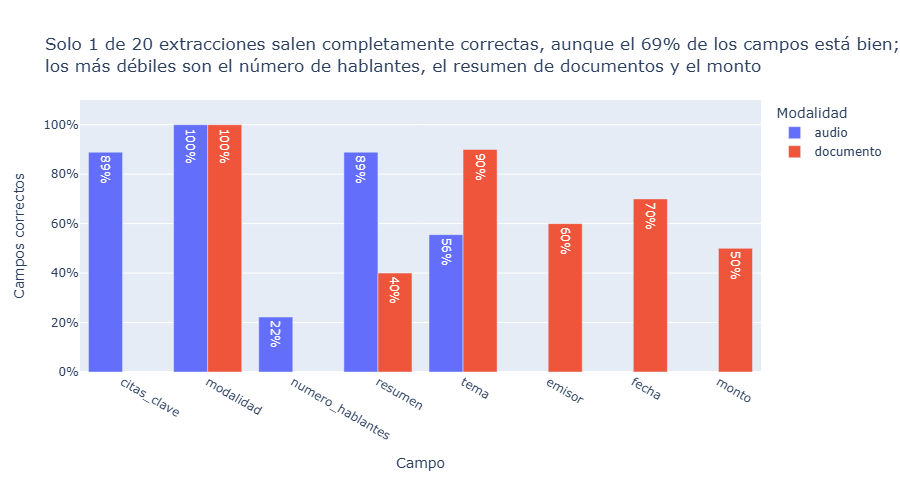

In [18]:
por_campo = (hoja[hoja["campo"] != "JSON inválido"].groupby(["modalidad", "campo"])["correcto"]
             .agg(correctos="sum", revisados="size").reset_index())
por_campo["acierto"] = por_campo["correctos"] / por_campo["revisados"]
fig_aud = px.bar(por_campo, x="campo", y="acierto", color="modalidad", barmode="group", text_auto=".0%",
                 title=f"Solo {ACUERDO} de 20 extracciones salen completamente correctas, aunque el {hoja['correcto'].mean():.0%} de los campos está bien;<br>los más débiles son el número de hablantes, el resumen de documentos y el monto",
                 labels={"acierto": "Campos correctos", "campo": "Campo", "modalidad": "Modalidad"})
fig_aud.update_yaxes(tickformat=".0%", range=[0, 1.1])
fig_aud.show()

In [19]:
print("Ejemplos de errores (campos marcados «No»):")
hoja.loc[~hoja["correcto"], ["id", "campo", "valor_llm", "comentario"]]

Ejemplos de errores (campos marcados «No»):


,id,campo,valor_llm,comentario
3,doc_004,emisor,EL LIBERTADOR [PERSONA_26],Debió salir el nombre del Presidente de la República
8,doc_008,resumen,"El joven [PERSONA_31] está practicando ascensiones en Milán, construyendo un aerostat ...",Debe decior el nombre completo de la persona ya es un recorte de periódico público. Ad...
10,doc_008,fecha,2023,No puedo dar fe si fue publicado el año 2023. En el documento no se visualiza
11,doc_008,monto,S/ 15.00,No menciona monto
15,doc_011,emisor,[PERSONA_34],Se debería colocar el nombre de la persona. Es público
16,doc_011,fecha,18-1190628,Menciona la fecha de vida del personaje: 1860-1928. Del año 1935
17,doc_011,monto,S/ 15.00,No menciona monto
23,doc_014,monto,S/ 28.00,No menciona monto
26,doc_016,resumen,"PRESIDENCIA DE LA REPUBLICA, GOBIERNO REGIONAL INKA, OBRA:CULMINACION ESTACION FERROVI...","Deberia decir ""AGUAS CALIENTES..."""
27,doc_016,emisor,ING- [PERSONA_36],Deberia salir el nombre del Ing. Presidente [PERSONA_36]


**Lectura de la auditoría**

- **1 de 20 extracciones está completamente correcta** (`doc_024`), aunque 73 de los 106 campos (69 %)
  están bien. Con la regla de «todos los campos bien», un solo campo dudoso hace perder la extracción.
- **Errores claros del LLM:**
  - **Montos inventados.** «S/ 15.00» aparece en 8 de los 25 documentos y es el ejemplo del prompt
    copiado: solo `doc_011` tiene un «15» en el texto, y la auditoría confirma que no es un monto. También inventa «S/ 28.00» en
    `doc_014` y convierte los años de la placa `doc_012` en «S/ 1570 - 1615».
  - **Fechas sin sustento:** «2023» en `doc_008` y «18-1190628» en `doc_011`.
  - **Resúmenes que copian o confunden el texto:** en `doc_016` copia el letrero en vez de resumirlo, y
    en `doc_017` y `doc_018` llama «lista de ingredientes» a la carta de un restaurante.
  - **Temas pobres:** «ve» (`clip_029`), «amar» (`clip_010`) y «votar» (`clip_021`).
  - **JSON inválido** en `clip_003`: la respuesta se repite hasta cortarse.
- **Fallas que vienen de la entrada, no del LLM.** Los comentarios muestran que varios «No» se
  juzgaron contra el archivo original, no contra el texto que recibió el LLM:
  - **`numero_hablantes`** (2 de 9 correctos). En 5 de los 7 «No», el LLM siguió la regla del prompt:
    null si no hay marcas `[HABLANTE_N]`, o el mismo número de marcas. Pero en el audio se oye una sola
    voz. El error viene de la regla del prompt y de la diarización. En un entorno real, el prompt debe
    pedir «1» cuando no hay marcas.
  - **`emisor` con `[PERSONA_NN]`** (`doc_004`, `doc_011` y `doc_016`). La persona que auditó esperaba
    el nombre de una figura pública, pero la seudonimización lo quita antes de que el texto llegue al
    LLM. Ese es el costo de la política de privacidad.
  - **`doc_026`.** El OCR leyó «MIRMOAY CIONA Orguilaea» y el LLM resumió eso. La auditoría lo juzgó
    contra la pancarta: un OCR malo arrastra al LLM.
- **En suma**, el 1/20 mide la cadena completa (OCR o ASR, seudonimización y LLM) frente a lo que ve o
  escucha una persona. Qwen3-0.6B en CPU produce JSON válido casi siempre (52 de 53), pero inventa datos
  y no sirve sin revisión humana.

## 4. Mejora y comparación de modelos

Cada modalidad tiene un modelo alternativo que se corre sobre **los mismos 10 archivos** y se mide con
**la misma normalización**. Sus configuraciones están en `modelos/configuracion_evaluacion.json` y se
fijaron antes de ver ninguna métrica. Las salidas también se seudonimizan antes de compararse.

### 4.1 Documentos: PaddleOCR frente a EasyOCR

- **Por qué EasyOCR:** es otra familia de modelos. Usa el detector CRAFT y un reconocedor CRNN
  (JaidedAI), mientras PaddleOCR usa PP-OCR (Baidu). El enunciado sugiere Tesseract, pero en Windows
  necesita un instalador con permisos de administrador. EasyOCR se instala con `pip` y también es un modelo
  de lectura de texto preentrenado.
- **Configuración:** EasyOCR 1.7.2, `lang=es`, CPU y el mismo preprocesamiento de la línea base (lado
  mayor de 2000 px). Las cajas se ordenan en renglones de arriba abajo y, dentro de cada renglón, de
  izquierda a derecha, igual que la regla de las referencias.
- **Entorno aparte:** EasyOCR trae `opencv-python-headless`, que choca con el OpenCV de PaddleOCR, así
  que corre con `uv run` en un entorno temporal. El script es `ocr_easyocr.py`.

In [20]:
OCR_ALT = EVAL_DIR / "ocr_easyocr.jsonl"
hechos = len(OCR_ALT.read_text(encoding="utf-8").splitlines()) if OCR_ALT.exists() else 0
if hechos < len(IDS_DOC):
    subprocess.run(["uv", "run", "--no-project", "--python", "3.12", "--with", "easyocr==1.7.2", "--with", "pandas",
                    "python", "ocr_easyocr.py"], check=True)
easy = pd.DataFrame(map(json.loads, OCR_ALT.read_text(encoding="utf-8").splitlines())).set_index("id").loc[IDS_DOC]
print(f"EasyOCR: {len(easy)} documentos leídos de {OCR_ALT.relative_to(BASE)} | {easy['modelo_ocr'].iloc[0]}")

seud_easy = {i: seudonimizar_texto(i, t) for i, t in easy["texto"].items()}
print(f"Seudonimización de EasyOCR: {sum(sum(c.values()) for _, c in seud_easy.values())} menciones reemplazadas")
alt_doc = base_doc[["id", "modalidad", "tipo", "referencia"]].assign(
    modelo="EasyOCR", rol="alternativo", texto=[seud_easy[i][0] for i in IDS_DOC], segundos=easy["segundos"].values)
alt_doc = evaluar(alt_doc, "caracter")
print(f"EasyOCR: CER global {tasa_global(alt_doc):.3f} | media por documento {alt_doc['tasa'].mean():.3f} "
      f"| {alt_doc['segundos'].mean():.0f} s por documento")

EasyOCR: 10 documentos leídos de datos\raw\evaluacion\ocr_easyocr.jsonl | EasyOCR 1.7.2 (CRAFT + CRNN latin, lang=es, CPU, lado máx. 2000 px, orden por renglones)
Seudonimización de EasyOCR: 5 menciones reemplazadas
EasyOCR: CER global 0.089 | media por documento 0.294 | 23 s por documento


### 4.2 Audio: faster-whisper `small` frente a Qwen3-ASR 0.6B

- **Por qué Qwen3-ASR 0.6B:** es uno de los modelos que propone el enunciado y ya está en `voz.py`
  (Sesión 13). Reconoce español y, con 0,6 B de parámetros, corre en esta CPU. Su arquitectura es distinta
  de Whisper: un codificador de audio conectado a un modelo de lenguaje Qwen3. MMS es mejor opción para
  lenguas con pocos datos, como el quechua, que no está en esta muestra.
- **Configuración:** `transformers` en CPU, float32, `language="es"`. Cada modelo usa su procedimiento
  estándar de `voz.py`: faster-whisper aplica su propio VAD, y Qwen3-ASR transcribe los tramos que
  corta el VAD Silero (pausas de 0,3 s y 12 s como máximo).
- **Latencia:** el factor de tiempo real es el tiempo de cálculo dividido entre la duración del audio.
  Un factor de 0,5 significa que un minuto de audio se transcribe en 30 s. No incluye la carga del modelo,
  que se hace una sola vez. En la línea base se usa el tiempo de transcripción de la Parte 1, sin la
  diarización.

In [21]:
CLAVE_ASR = "qwen3-asr-0.6b"
ASR_ALT = EVAL_DIR / f"asr_{CLAVE_ASR}.jsonl"
config_asr = CONFIG["modelos"]["asr_alternativo"]
hechos = {f["id"] for f in map(json.loads, ASR_ALT.read_text(encoding="utf-8").splitlines())} if ASR_ALT.exists() else set()
pendientes = [i for i in IDS_AUD if i not in hechos]
if pendientes:
    from huggingface_hub import snapshot_download
    carpeta = RAW / "modelos" / "Qwen3-ASR-0.6B-hf"
    snapshot_download(config_asr["hf"], local_dir=carpeta)
    voz.MODELOS[CLAVE_ASR]["hf"] = str(carpeta)
    transcriptor = voz.Transcriptor(CLAVE_ASR, device="cpu")
    for id_ in pendientes:
        audio = voz.cargar_audio(BASE / clip_idx.loc[id_, "archivo_audio"])
        t0 = time.perf_counter()
        segs = transcriptor.segmentos(audio, idioma="es")
        seg = time.perf_counter() - t0
        fila = {"id": id_, "texto": " ".join(s.texto for s in segs), "duracion_seg": round(len(audio) / voz.SR, 2),
                "segundos_calculo": round(seg, 2), "factor_tiempo_real": round(seg / (len(audio) / voz.SR), 3),
                "modelo_asr": "Qwen3-ASR 0.6B (transformers, CPU, float32, VAD Silero de voz.py, tramos de 12 s, idioma=es)"}
        with ASR_ALT.open("a", encoding="utf-8") as f:
            f.write(json.dumps(fila, ensure_ascii=False) + "\n")

qwen = pd.DataFrame(map(json.loads, ASR_ALT.read_text(encoding="utf-8").splitlines())).set_index("id").loc[IDS_AUD]
print(f"Qwen3-ASR: {len(qwen)} clips leídos de {ASR_ALT.relative_to(BASE)} | {qwen['modelo_asr'].iloc[0]}")

seud_qwen = {i: seudonimizar_texto(i, t) for i, t in qwen["texto"].items()}
print(f"Seudonimización de Qwen3-ASR: {sum(sum(c.values()) for _, c in seud_qwen.values())} menciones reemplazadas")
alt_aud = base_aud[["id", "modalidad", "tipo", "referencia", "duracion_seg"]].assign(
    modelo="Qwen3-ASR 0.6B", rol="alternativo", texto=[seud_qwen[i][0] for i in IDS_AUD],
    segundos=qwen["segundos_calculo"].values)
alt_aud["factor_tiempo_real"] = alt_aud["segundos"] / alt_aud["duracion_seg"]
alt_aud = evaluar(alt_aud, "palabra")
print(f"Qwen3-ASR: WER global {tasa_global(alt_aud):.3f} | media por clip {alt_aud['tasa'].mean():.3f} "
      f"| factor de tiempo real medio {alt_aud['factor_tiempo_real'].mean():.2f}")

Qwen3-ASR: 10 clips leídos de datos\raw\evaluacion\asr_qwen3-asr-0.6b.jsonl | Qwen3-ASR 0.6B (transformers, CPU, float32, VAD Silero de voz.py, tramos de 12 s, idioma=es)
Seudonimización de Qwen3-ASR: 6 menciones reemplazadas
Qwen3-ASR: WER global 0.210 | media por clip 0.150 | factor de tiempo real medio 0.92


In [22]:
# Revisión de privacidad de las salidas alternativas: candidatos PER que no son seudónimos
quedan_alt = pd.DataFrame([{"id": i, "modelo": m, "candidato": c}
                           for m, textos in [("EasyOCR", seud_easy), ("Qwen3-ASR 0.6B", seud_qwen)]
                           for i, (t, _) in textos.items() for c in candidatos_per(t)],
                          columns=["id", "modelo", "candidato"])
quedan_alt["decisión"] = quedan_alt["candidato"].map(SE_MANTIENEN_REF)
assert quedan_alt["decisión"].notna().all(), "Hay candidatos sin revisar: revisarlos antes de publicar"
print(f"Candidatos PER que quedan en las salidas alternativas: {len(quedan_alt)}, todos revisados a mano")

Candidatos PER que quedan en las salidas alternativas: 25, todos revisados a mano


In [23]:
resultados = pd.concat([base_doc, alt_doc, base_aud, alt_aud], ignore_index=True)
resultados["metrica"] = np.where(resultados["modalidad"] == "documento", "CER", "WER")
evaluacion_modelos = resultados[["id", "modalidad", "tipo", "modelo", "rol", "metrica", "tasa", "errores", "unidades",
                                 "segundos", "duracion_seg", "factor_tiempo_real", "texto", "referencia"]].rename(
    columns={"tasa": "valor", "texto": "texto_modelo", "referencia": "texto_referencia"})
evaluacion_modelos.to_csv(SALIDA / "evaluacion_modelos.csv", index=False)
print(f"datos/evaluacion_modelos.csv: shape {evaluacion_modelos.shape} (20 archivos x 2 modelos, textos seudonimizados)")
evaluacion_modelos.pivot_table(index=["modalidad", "id"], columns="modelo", values="valor").round(3)

datos/evaluacion_modelos.csv: shape (40, 14) (20 archivos x 2 modelos, textos seudonimizados)


modelo              EasyOCR  PaddleOCR (base)  Qwen3-ASR 0.6B  faster-whisper small (base)
modalidad id                                                                              
audio     clip_010      NaN               NaN           0.151                        0.017
          clip_011      NaN               NaN           0.363                        0.074
          clip_013      NaN               NaN           0.309                        0.108
          clip_015      NaN               NaN           0.122                        0.027
          clip_016      NaN               NaN           0.093                        0.000
          clip_017      NaN               NaN           0.062                        0.000
          clip_023      NaN               NaN           0.111                        0.111
          clip_027      NaN               NaN           0.214                        0.000
          clip_028      NaN               NaN           0.000                        0.000
          clip_029      NaN               NaN           0.077                        0.154
documento doc_004     0.016             0.001             NaN                          NaN
          doc_005     0.029             0.007             NaN                          NaN
          doc_006     0.049             0.001             NaN                          NaN
          doc_012     0.373             0.020             NaN                          NaN
          doc_013     0.393             0.732             NaN                          NaN
          doc_014     0.085             0.019             NaN                          NaN
          doc_020     0.450             0.064             NaN                          NaN
          doc_023     0.495             0.194             NaN                          NaN
          doc_025     0.382             0.141             NaN                          NaN
          doc_026     0.674             0.609             NaN                          NaN

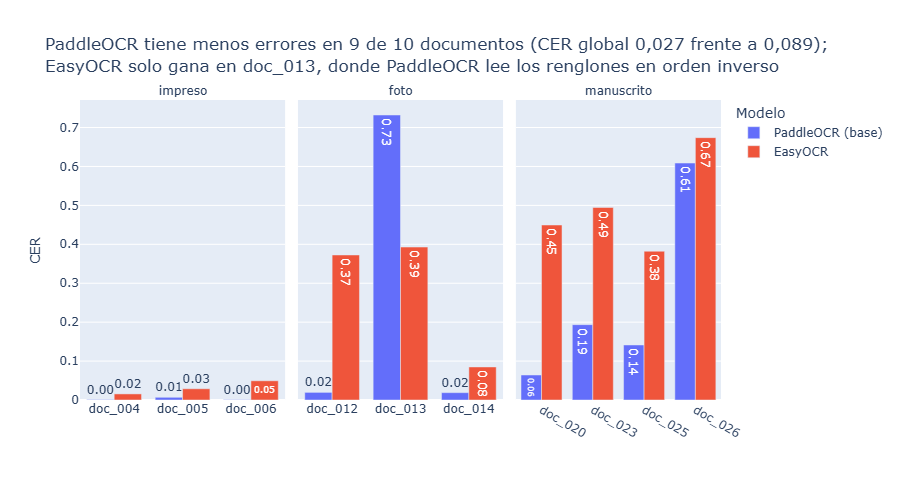

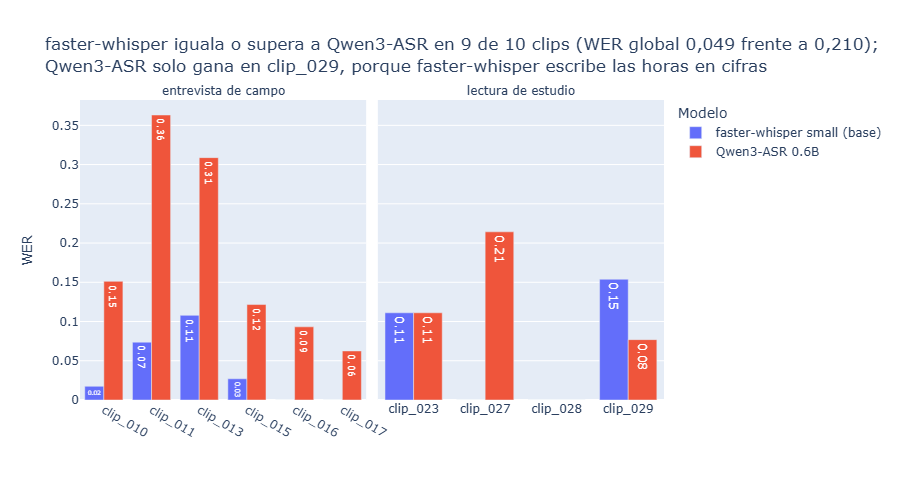

In [24]:
fig_doc = px.bar(resultados[resultados["modalidad"] == "documento"], x="id", y="tasa", color="modelo", barmode="group",
                 facet_col="tipo", category_orders={"tipo": ["impreso", "foto", "manuscrito"]}, text_auto=".2f",
                 title="PaddleOCR tiene menos errores en 9 de 10 documentos (CER global 0,027 frente a 0,089);<br>EasyOCR solo gana en doc_013, donde PaddleOCR lee los renglones en orden inverso", labels={"tasa": "CER", "id": "", "modelo": "Modelo"})
fig_doc.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig_doc.update_xaxes(matches=None)
fig_doc.show()

fig_aud_cmp = px.bar(resultados[resultados["modalidad"] == "audio"], x="id", y="tasa", color="modelo", barmode="group",
                     facet_col="tipo", text_auto=".2f", title="faster-whisper iguala o supera a Qwen3-ASR en 9 de 10 clips (WER global 0,049 frente a 0,210);<br>Qwen3-ASR solo gana en clip_029, porque faster-whisper escribe las horas en cifras",
                     labels={"tasa": "WER", "id": "", "modelo": "Modelo"})
fig_aud_cmp.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig_aud_cmp.update_xaxes(matches=None)
fig_aud_cmp.show()

**Lectura de la comparación**

- **Documentos.** PaddleOCR comete 3,3 veces menos errores que EasyOCR: 136 frente a 445, con un CER
  global de 0,027 frente a 0,089. Gana en 9 de los 10 documentos. EasyOCR solo gana en `doc_013`, porque
  respeta el orden de los renglones, aunque cambia letras. EasyOCR es más rápido (23 s frente a 56 s por
  documento) y más liviano (94 MB frente a 146 MB), pero la diferencia de precisión pesa más.
- **Audio.** faster-whisper comete 4,3 veces menos errores: 44 frente a 189, con un WER de 0,049 frente
  a 0,210. Gana en 7 clips, empata en 2 (`clip_023` y `clip_028`) y solo pierde en `clip_029`, por
  escribir las horas en cifras. Además es casi el doble de rápido: su factor de tiempo real es 0,57,
  frente a 1,04 de Qwen3-ASR, que tarda más que el propio audio. Y ocupa la tercera parte del disco
  (464 MB frente a 1 503 MB).
- Qwen3-ASR une o parte palabras («a parte», «sembrillos»), repite frases en los cortes del VAD y
  hace frases sin sentido. Como transcribe tramos de 12 s como máximo, probablemente pierde contexto entre cortes.
- La comparación es pareja: los mismos 20 archivos, la misma normalización y configuraciones fijadas
  antes de medir. Con 10 archivos por modalidad, la ventaja de la línea base es grande y constante en
  audio, y en documentos tiene una sola excepción.

## 5. Casos difíciles

### 5.1 Documentos: impresos, fotos y manuscritos

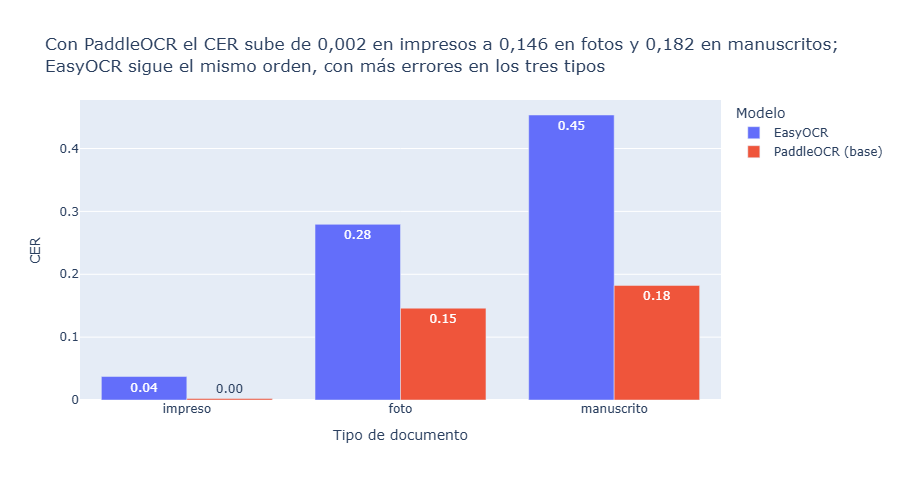

modelo,EasyOCR,PaddleOCR (base)
tipo,,
impreso,0.037,0.002
foto,0.279,0.146
manuscrito,0.453,0.182


In [25]:
por_tipo = (resultados[resultados["modalidad"] == "documento"].groupby(["tipo", "modelo"])
            .agg(errores=("errores", "sum"), caracteres=("unidades", "sum"), documentos=("id", "size")).reset_index())
por_tipo["CER"] = por_tipo["errores"] / por_tipo["caracteres"]
fig_tipo = px.bar(por_tipo, x="tipo", y="CER", color="modelo", barmode="group", text_auto=".2f",
                  category_orders={"tipo": ["impreso", "foto", "manuscrito"]}, title="Con PaddleOCR el CER sube de 0,002 en impresos a 0,146 en fotos y 0,182 en manuscritos;<br>EasyOCR sigue el mismo orden, con más errores en los tres tipos",
                  labels={"tipo": "Tipo de documento", "modelo": "Modelo"})
fig_tipo.show()
por_tipo.pivot_table(index="tipo", columns="modelo", values="CER").loc[["impreso", "foto", "manuscrito"]].round(3)

In [26]:
def comparar(id_, modelo, n=400):
    """Referencia y salida normalizadas, una debajo de la otra (textos seudonimizados)."""
    f = resultados[(resultados["id"] == id_) & (resultados["modelo"] == modelo)].iloc[0]
    print(f"{id_} · {modelo} · {f['tipo']} · {'CER' if f['modalidad'] == 'documento' else 'WER'} {f['tasa']:.2f}")
    print("  referencia:", normalizar_eval(f["referencia"])[:n])
    print("  modelo:    ", normalizar_eval(f["texto"])[:n] or "(vacío)", "\n")


docs_res = resultados[resultados["modalidad"] == "documento"]
for tipo in ["manuscrito", "foto"]:
    peor = docs_res[(docs_res["tipo"] == tipo) & (docs_res["rol"] == "base")].sort_values("tasa").iloc[-1]["id"]
    for modelo in ["PaddleOCR (base)", "EasyOCR"]:
        comparar(peor, modelo)

doc_026 · PaddleOCR (base) · manuscrito · CER 0.61
  referencia: mi amor por ti es incondicional orgullosa mamá
  modelo:     mirmoay ciona orguilaea 

doc_026 · EasyOCR · manuscrito · CER 0.67
  referencia: mi amor por ti es incondicional orgullosa mamá
  modelo:     mi l por uo koj zuca acz 

doc_013 · PaddleOCR (base) · foto · CER 0.73
  referencia: paraninfo universitario antiguo convento de los jesuitas
  modelo:     tesuitas los convento de antiguo universitario paraninfo 

doc_013 · EasyOCR · foto · CER 0.39
  referencia: paraninfo universitario antiguo convento de los jesuitas
  modelo:     faranineo gmaersiario anelicek csavento de lc olas 



### 5.2 Audio: estudio frente a calle

Las frases de OpenSLR 73 se grabaron en estudio, con una sola voz. Las entrevistas de Commons se grabaron
en la calle o en fiestas, con varias voces. Para medir el ruido sin depender de una etiqueta manual, se
estima la relación señal-ruido de cada clip con el VAD. Se compara la energía de los tramos con voz con la
de los tramos sin voz. Con poco ruido de fondo (o pausas en silencio), el valor en dB es alto.

In [27]:
def senal_ruido(ruta):
    """Relación entre la energía de los tramos con voz y la de los tramos sin voz (dB), según el VAD Silero."""
    audio = voz.cargar_audio(ruta)
    con_voz = np.zeros(len(audio), dtype=bool)
    for a, b in voz.tramos_de_voz(audio):
        con_voz[int(a * voz.SR):int(b * voz.SR)] = True
    if (~con_voz).sum() < 0.2 * voz.SR:        # casi sin pausas: no hay ruido de fondo que medir
        return np.nan, con_voz.mean()
    rms = lambda x: np.sqrt(np.mean(np.square(x))) + 1e-9
    return 20 * np.log10(rms(audio[con_voz]) / rms(audio[~con_voz])), con_voz.mean()


condicion = pd.DataFrame([(i, *senal_ruido(BASE / clip_idx.loc[i, "archivo_audio"])) for i in IDS_AUD],
                         columns=["id", "snr_db", "fraccion_voz"])
condicion["hablantes"] = clip_idx.loc[IDS_AUD, "n_hablantes"].values
condicion["señal-ruido"] = condicion["snr_db"].map(lambda x: "sin pausas" if pd.isna(x) else f"{x:.1f} dB")
condicion["descripción"] = condicion["id"].map(descripcion)
aud_res = resultados[resultados["modalidad"] == "audio"].merge(condicion, on="id")
display(aud_res.pivot_table(index=["tipo", "id", "señal-ruido", "hablantes"], columns="modelo", values="tasa").round(3))

por_condicion = (aud_res.groupby(["tipo", "modelo"]).agg(errores=("errores", "sum"), palabras=("unidades", "sum"),
                                                        clips=("id", "size")).reset_index())
por_condicion["WER"] = por_condicion["errores"] / por_condicion["palabras"]
por_condicion.pivot_table(index="tipo", columns="modelo", values="WER").round(3)

modelo                                              Qwen3-ASR 0.6B  faster-whisper small (base)
tipo                id       señal-ruido hablantes                                             
entrevista de campo clip_010 1.6 dB      2                   0.151                        0.017
                    clip_011 2.4 dB      8                   0.363                        0.074
                    clip_013 5.6 dB      2                   0.309                        0.108
                    clip_015 33.3 dB     1                   0.122                        0.027
                    clip_016 16.0 dB     1                   0.093                        0.000
                    clip_017 20.5 dB     1                   0.062                        0.000
lectura de estudio  clip_023 10.1 dB     1                   0.111                        0.111
                    clip_027 16.5 dB     1                   0.214                        0.000
                    clip_028 30.5 dB     1                   0.000                        0.000
                    clip_029 55.8 dB     1                   0.077                        0.154

modelo,Qwen3-ASR 0.6B,faster-whisper small (base)
tipo,,
entrevista de campo,0.215,0.048
lectura de estudio,0.114,0.068


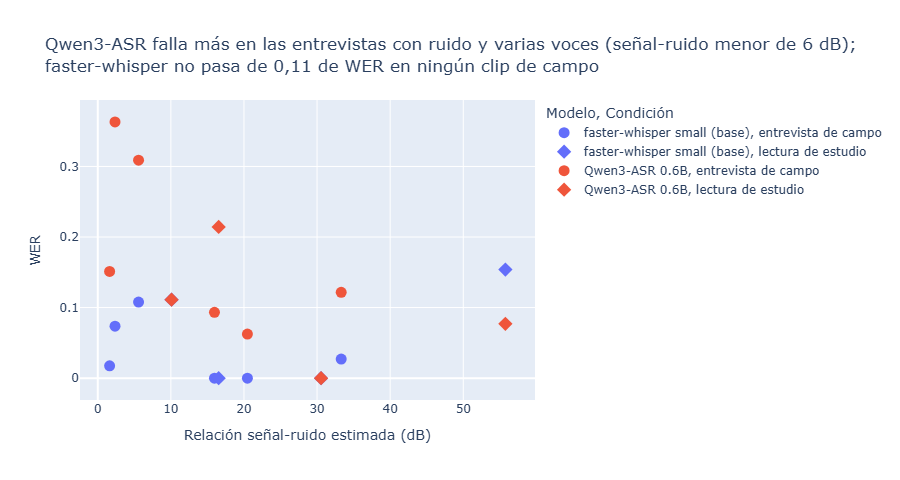

clip_029 · faster-whisper small (base) · lectura de estudio · WER 0.15
  referencia: ellos ven la tele entre la una y las tres de la tarde
  modelo:     ellos ven la tele entre la 1 y las 3 de la tarde 

clip_029 · Qwen3-ASR 0.6B · lectura de estudio · WER 0.08
  referencia: ellos ven la tele entre la una y las tres de la tarde
  modelo:     ellos ven la tele entre las una y las tres de la tarde 

clip_016 · faster-whisper small (base) · entrevista de campo · WER 0.00
  referencia: una de las anécdotas que ha marcado mi vida es cuando estuve muy pequeña y mis padres también se dedicaban a la siembra de coca pero vino la radicación y con todos los vecinos todas las partes que sembraban se vieron afectados porque no tenían otro tipo de sembrío sin radicar una coca de raíz y fue 
  modelo:     una de las anécdotas que ha marcado mi vida es cuando estuve muy pequeña y mis padres también se dedicaban a la siembra de coca pero vino la radicación y con todos los vecinos todas las partes que s

In [28]:
fig_snr = px.scatter(aud_res, x="snr_db", y="tasa", color="modelo", symbol="tipo", hover_name="id",
                     hover_data={"hablantes": True, "descripción": True}, title="Qwen3-ASR falla más en las entrevistas con ruido y varias voces (señal-ruido menor de 6 dB);<br>faster-whisper no pasa de 0,11 de WER en ningún clip de campo",
                     labels={"snr_db": "Relación señal-ruido estimada (dB)", "tasa": "WER", "modelo": "Modelo", "tipo": "Condición"})
fig_snr.update_traces(marker_size=11)
fig_snr.show()

aud_base = aud_res[aud_res["rol"] == "base"].sort_values("tasa")
for id_ in [aud_base.iloc[-1]["id"], aud_base.iloc[0]["id"]]:
    for modelo in ["faster-whisper small (base)", "Qwen3-ASR 0.6B"]:
        comparar(id_, modelo, n=300)

**Lectura de los casos difíciles**

- **Documentos.** El tipo de documento pesa más que el modelo. Con PaddleOCR, el CER pasa de 0,002 en
  impresos a 0,146 en fotos y 0,182 en manuscritos. EasyOCR sigue el mismo orden: 0,037, 0,279 y 0,453.
  - La letra cursiva es el peor caso. En `doc_026` («mi amor por ti es incondicional, orgullosa mamá»)
    ningún modelo lee una frase reconocible.
  - En las fotos, los problemas son el orden y el relieve. En `doc_013`, de letras metálicas con sombra,
    PaddleOCR invierte los renglones. En la placa de bronce oscuro de `doc_012`, EasyOCR falla y
    PaddleOCR no.
- **Audio.** La relación señal-ruido explica bien los errores de Qwen3-ASR. Sus tres peores clips (WER
  de 0,15 a 0,36) son entrevistas de campo con menos de 6 dB y dos o más voces: `clip_010`, `clip_011`
  y `clip_013`. faster-whisper también tiene ahí sus mayores errores de campo, pero no pasa de 0,108.
- **Cuidado con las tasas por grupo.** faster-whisper tiene más WER en estudio (0,068) que en la calle
  (0,048), pero no porque el estudio sea más difícil. Las 4 frases suman 44 palabras, así que cada error
  pesa 2,3 puntos, y sus 3 errores son las cifras de `clip_029` y «reguardar». Con muestras tan
  pequeñas, una tasa por grupo puede engañar; por eso se muestran también los clips uno por uno.
  Qwen3-ASR sí sigue el orden esperado: 0,114 en estudio y 0,215 en la calle.

## 6. Comparativa y decisión

In [29]:
def megabytes(*carpetas):
    total = sum(p.stat().st_size for c in carpetas if c.exists() for p in c.rglob("*") if p.is_file())
    return round(total / 2**20) if total else np.nan


paddlex = Path.home() / ".paddlex" / "official_models"
hf = Path.home() / ".cache" / "huggingface" / "hub"
tamaño = {
    "PaddleOCR (base)": megabytes(*(paddlex / m for m in ["PP-OCRv6_medium_det", "PP-OCRv6_medium_rec",
                                                          "PP-LCNet_x1_0_doc_ori", "PP-LCNet_x1_0_textline_ori"])),
    "EasyOCR": megabytes(RAW / "modelos" / "easyocr"),
    "faster-whisper small (base)": megabytes(hf / "models--Systran--faster-whisper-small" / "snapshots"),   # en Windows la caché no usa enlaces simbólicos
    "Qwen3-ASR 0.6B": megabytes(RAW / "modelos" / "Qwen3-ASR-0.6B-hf"),
}

filas = []
for (modalidad, modelo), g in resultados.groupby(["modalidad", "modelo"], sort=False):
    fila = {"modalidad": modalidad, "modelo": modelo, "rol": g["rol"].iloc[0],
            "métrica": "CER" if modalidad == "documento" else "WER",
            "global": tasa_global(g), "media por archivo": g["tasa"].mean()}
    for tipo, gt in g.groupby("tipo"):
        fila[tipo] = tasa_global(gt)
    if modalidad == "documento":
        fila["latencia"] = f"{g['segundos'].mean():.0f} s por documento"
    else:
        fila["latencia"] = f"factor de tiempo real {g['segundos'].sum() / g['duracion_seg'].sum():.2f} (total), {g['factor_tiempo_real'].mean():.2f} (media por clip)"
    fila["tamaño en disco (MB)"] = tamaño[modelo]
    fila["costo"] = "CPU, sin GPU, gratis y local"
    filas.append(fila)
comparativa = pd.DataFrame(filas)
comparativa = comparativa[["modalidad", "modelo", "rol", "métrica", "global", "media por archivo", "impreso", "foto",
                           "manuscrito", "lectura de estudio", "entrevista de campo", "latencia", "tamaño en disco (MB)", "costo"]]
comparativa.round(3).astype(object).fillna("")

,modalidad,modelo,rol,métrica,global,media por archivo,impreso,foto,manuscrito,lectura de estudio,entrevista de campo,latencia,tamaño en disco (MB),costo
0,documento,PaddleOCR (base),base,CER,0.027,0.179,0.002,0.146,0.182,,,56 s por documento,146,"CPU, sin GPU, gratis y local"
1,documento,EasyOCR,alternativo,CER,0.089,0.294,0.037,0.279,0.453,,,23 s por documento,94,"CPU, sin GPU, gratis y local"
2,audio,faster-whisper small (base),base,WER,0.049,0.049,,,,0.068,0.048,"factor de tiempo real 0.57 (total), 0.82 (media por clip)",464,"CPU, sin GPU, gratis y local"
3,audio,Qwen3-ASR 0.6B,alternativo,WER,0.21,0.15,,,,0.114,0.215,"factor de tiempo real 1.04 (total), 0.92 (media por clip)",1503,"CPU, sin GPU, gratis y local"


### Decisión para un entorno real

Escenario: un archivo municipal o una ONG que quiere volver buscables sus documentos y entrevistas en
una computadora común, sin GPU y sin enviar datos fuera.

| Pieza | Elección | Por qué |
|---|---|---|
| OCR | **PaddleOCR** (PP-OCRv6 medium) | Comete 3,3 veces menos errores que EasyOCR. Tarda 56 s por página en esta CPU, aceptable para procesar en lote |
| ASR | **faster-whisper `small`** | Comete 4,3 veces menos errores que Qwen3-ASR, es casi el doble de rápido y ocupa la tercera parte del disco |
| LLM | **Qwen3-0.6B solo como borrador** | Solo 1 de 20 extracciones completamente correctas en la auditoría. No sirve sin revisión humana |

**Condiciones para usarlo:**
- **Revisión humana de manuscritos y fotos difíciles.** Un CER de 0,18 en manuscritos es casi un error
  cada cinco caracteres. Los impresos, en cambio, salen casi perfectos.
- **LLM:**
  - Quitar del prompt el ejemplo «S/ 15.00».
  - Rechazar los montos y las fechas que no aparezcan en el texto.
  - Pedir «1» como número de hablantes cuando no hay marcas.
  - Probar un modelo más grande (por ejemplo, Qwen3-4B) en una máquina con GPU o más memoria.
- **Privacidad.** Todo corre en local y los nombres se reemplazan antes del LLM. Si la institución
  quiere conservar los nombres de figuras públicas, como pidió la auditoría, debe decidirlo de forma
  explícita.

**Limitaciones:** 10 archivos por modalidad, una sola persona en la auditoría y tiempos medidos en un
solo equipo.

### Resultados para la entrega

Las cifras que se copian en el comentario de entrega son las de los modelos elegidos para el entorno
real, medidas en los mismos 10 documentos y los mismos 10 clips.

In [30]:
ELEGIDO_OCR, ELEGIDO_ASR = "PaddleOCR (base)", "faster-whisper small (base)"
CER_FINAL = tasa_global(resultados[resultados["modelo"] == ELEGIDO_OCR])
WER_FINAL = tasa_global(resultados[resultados["modelo"] == ELEGIDO_ASR])
print(f"OCR elegido: {ELEGIDO_OCR} | ASR elegido: {ELEGIDO_ASR}")
print(f"Resultados Test: WER: {WER_FINAL:.2f} | CER: {CER_FINAL:.2f} | Acuerdo LLM-Humano: {ACUERDO}/20")

OCR elegido: PaddleOCR (base) | ASR elegido: faster-whisper small (base)
Resultados Test: WER: 0.05 | CER: 0.03 | Acuerdo LLM-Humano: 1/20
